# Exploración y limpieza de un dataset — Protocolo EDA del Detective

**Seminario de Investigación II** · Dataset: *Common Voice 27.0*, quechua sureño (`qxp`), subconjunto `validated`.
Corpus base del Proyecto IA (ASR quechua) de la tesis.

Se sigue el **protocolo de 5 pasos / 8 herramientas** del material del curso (Msc. Raúl Huillca Huallparimachi):

| Paso | Qué revisa | Herramientas |
|---|---|---|
| **0 · Primer Vistazo** | Forma del dataset | `head`, `info`, `describe` |
| **1 · Escena del Crimen** | Calidad | Nulos, duplicados, errores → **limpieza** |
| **2 · Anatomía Numérica** | Una variable | Histograma, **caja y bigotes**, barras |
| **3 · Conexiones Ocultas** | Dos variables | Dispersión, **Pearson**, **Spearman**, **mapa de calor** |
| **4 · Variable Objetivo** | Lo que importa | Gráficos cruzados |

> **Rigurosidad.** *Metodológica*: orden estricto; cada decisión se toma sobre evidencia numérica.
> *Teórica*: Pearson (lineal) y Spearman (monótona/robusta) complementarias; outliers por IQR (Tukey).
> *Interpretativa*: cada figura lleva su lectura. *Replicabilidad*: semilla fija, versiones registradas, salidas deterministas.

In [1]:
import sys, io
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import eda_limpieza as eda            # reutiliza la lógica del script (DRY, reproducible)
from IPython.display import Image

print('python', sys.version.split()[0], '| pandas', pd.__version__, '| numpy', np.__version__, '| SEED', eda.SEED)
df = eda.cargar()
print('Forma cruda:', df.shape)

python 3.13.3 | pandas 2.3.3 | numpy 2.3.2 | SEED 42


Forma cruda: (22727, 19)


## Paso 0 — El Primer Vistazo
> *Antes de dibujar nada, mira los números crudos para no entrenar con un dataset arruinado desde el inicio.*

`head()` (¿tiene sentido?), `info()` (tipos y no-nulos) y `describe()` (centro y rango al instante).

In [2]:
df.head()

,client_id,path,sentence_id,sentence,sentence_domain,up_votes,down_votes,age,gender,accents,variant,locale,segment,dur_ms,dur_s,n_chars,n_words,cps,net_votes
0,0af18d417177a707fb1bcb22e6b23aa10944f4e44ec80e...,common_voice_qxp_42192187.mp3,122e2be2a8a1f3f227f0752cf84e5946fd4b0c4e53ad4c...,Irqikuna paykunapura qatipayanakunku.,"agriculture_food,agriculture_food,finance,heal...",2,0,NaN,NaN,NaN,NaN,qxp,NaN,4968,4.968,37,3,7.447665,2
1,76b24fbe885ee8fdad9aa7dd591b82c6fa01fdc5eeb366...,common_voice_qxp_48799942.mp3,d29d38892e4b3567b7521914846f256a7a40089c9115bf...,Juan wayqichampaq waqayninta pichan.,"general,agriculture_food,nature_environment",4,0,thirties,NaN,Puno,NaN,qxp,NaN,5040,5.040,36,4,7.142857,4
2,87382b51a62cecd09092de5114d0bb779a4e61ce39e6e7...,common_voice_qxp_48816803.mp3,d858fd4486ab61cd0a4ff73466f8e236a4cb7b88484da9...,Hayk'aqmi runa Killaman chayarqan?,"general,agriculture_food,healthcare",6,0,twenties,female_feminine,Puno|Macusani - Puno,NaN,qxp,NaN,4860,4.860,34,4,6.995885,6
3,cbd0c73038ebd1636ed7d8211b650f8b4e47dedf03168b...,common_voice_qxp_48887267.mp3,5b4e0f5c19f8cf67909d4b80acdeca7382352a0a72dc90...,Pipaqmi kay qillqasqa?,"general,agriculture_food,healthcare",2,0,fifties,female_feminine,NaN,NaN,qxp,NaN,4680,4.680,22,3,4.700855,2
4,e0c301044db611e861f7117cfcc2ee744f03bffd69122a...,common_voice_qxp_48781894.mp3,d4e94ecb06930998e2e9ac40f49c3f5771081dd9d89897...,Iskay urququnaq chaupinpi payqa tiyan.,"general,agriculture_food,history_law_government",2,0,thirties,female_feminine,NaN,NaN,qxp,NaN,4896,4.896,38,5,7.761438,2


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22727 entries, 0 to 22726
Data columns (total 19 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   client_id        22727 non-null  object 
 1   path             22727 non-null  object 
 2   sentence_id      22727 non-null  object 
 3   sentence         22727 non-null  object 
 4   sentence_domain  22705 non-null  object 
 5   up_votes         22727 non-null  int64  
 6   down_votes       22727 non-null  int64  
 7   age              22494 non-null  object 
 8   gender           16387 non-null  object 
 9   accents          8371 non-null   object 
 10  variant          0 non-null      float64
 11  locale           22727 non-null  object 
 12  segment          0 non-null      float64
 13  dur_ms           22727 non-null  int64  
 14  dur_s            22727 non-null  float64
 15  n_chars          22727 non-null  int64  
 16  n_words          22727 non-null  int64  
 17  cps         

In [4]:
cols_num = ['dur_s','n_chars','n_words','cps','up_votes','down_votes','net_votes']
df[cols_num].describe().round(2)

,dur_s,n_chars,n_words,cps,up_votes,down_votes,net_votes
count,22727.00,22727.00,22727.00,22727.00,22727.00,22727.00,22727.00
mean,4.83,34.58,3.99,7.27,2.76,0.15,2.61
std,1.37,10.30,1.21,1.51,0.98,0.45,1.05
min,1.80,11.00,1.00,1.93,2.00,0.00,1.00
25%,3.89,28.00,3.00,6.28,2.00,0.00,2.00
50%,4.61,33.00,4.00,7.22,2.00,0.00,2.00
75%,5.51,40.00,5.00,8.20,4.00,0.00,4.00
max,14.94,83.00,10.00,15.65,8.00,6.00,6.00


**Lectura.** 22 727 clips × 13 columnas originales. Añadimos variables derivadas de *forma del habla*:
`dur_s` (duración), `n_chars`/`n_words` (longitud de la transcripción), `cps` (velocidad = caracteres/segundo)
y `net_votes` (`up−down`). Ya se intuye que `variant` y `segment` vienen vacías: candidatas a eliminar.

## Paso 1 — La Escena del Crimen (calidad)
> *Identifica y señala los errores críticos ANTES de cualquier análisis: nulos, duplicados y errores obvios.*

In [5]:
nulos = df.isna().sum(); pct = (nulos/len(df)*100).round(1)
pd.DataFrame({'nulos':nulos,'pct_%':pct}).sort_values('pct_%', ascending=False)

,nulos,pct_%
variant,22727,100.0
segment,22727,100.0
accents,14356,63.2
gender,6340,27.9
age,233,1.0
sentence_domain,22,0.1
client_id,0,0.0
sentence_id,0,0.0
path,0,0.0
sentence,0,0.0


**Nulos.** `variant` y `segment` están **100 %** vacías (sin información). `accents` **63 %** y `gender` **28 %**
faltantes: son metadatos *demográficos*, no invalidan el audio. `age` casi completo (1 %). Decisión razonada:
**no borrar filas** por demografía faltante (perderíamos hasta el 63 % del corpus) sino marcarla como `unknown`.

In [6]:
print('Filas idénticas  :', df.duplicated().sum())
print('Rutas repetidas  :', df['path'].duplicated().sum())
print('Frases únicas    :', df['sentence'].nunique(), '/', len(df),
      f"(~{len(df)/df['sentence'].nunique():.0f} grabaciones por frase)")

Filas idénticas  : 0
Rutas repetidas  : 0
Frases únicas    : 2067 / 22727 (~11 grabaciones por frase)


**Duplicados.** Cero filas o audios repetidos. Pero solo hay **2 067 frases únicas**: cada una se grabó
~11 veces por distintos hablantes. Esto **no es un error** (es deseable para ASR multi-hablante), pero obliga a
**particionar por frase/hablante** para evitar *fuga de datos* entre entrenamiento y prueba.

In [7]:
dom = df['sentence_domain'].fillna('unknown').str.split(',')
malform = dom.apply(lambda t: len(t)!=len(set(x.strip() for x in t)))
print('sentence_domain malformado (tokens repetidos):', int(malform.sum()))
print('Clips con net_votes<=0 (rechazos>=aceptaciones):', int((df['up_votes']-df['down_votes']<=0).sum()))

sentence_domain malformado (tokens repetidos): 76
Clips con net_votes<=0 (rechazos>=aceptaciones): 0


**Errores obvios.** `sentence_domain` es **multi-etiqueta** (p. ej. `general,agriculture_food,healthcare`);
**76 filas** repiten tokens internos (`healthcare,healthcare`) → se normalizan deduplicando. Ningún clip validado
tiene `net_votes≤0`. Ahora aplicamos la limpieza completa (elimina columnas inútiles, normaliza dominios,
imputa `unknown`, marca outliers):


PASO 1 — LA ESCENA DEL CRIMEN (calidad: nulos, duplicados, errores)

-- Nulos por columna --
                 nulos    pct
client_id            0    0.0
path                 0    0.0
sentence_id          0    0.0
sentence             0    0.0
sentence_domain     22    0.1
up_votes             0    0.0
down_votes           0    0.0
age                233    1.0
gender            6340   27.9
accents          14356   63.2
variant          22727  100.0
locale               0    0.0
segment          22727  100.0
dur_ms               0    0.0
dur_s                0    0.0
n_chars              0    0.0
n_words              0    0.0
cps                  0    0.0
net_votes            0    0.0



-- Duplicados --
Filas idénticas completas : 0
Rutas de audio repetidas  : 0
Frases únicas / total     : 2067 / 22727 (cada frase se grabó ~11 veces)
  -> Repetir una frase NO es un error (es multi-hablante), pero obliga a
     particionar por frase/hablante para evitar fuga de datos en train/test.

-- Errores obvios --
Filas con 'sentence_domain' malformado (tokens repetidos): 76
Clips con net_votes <= 0 (rechazos >= aceptaciones)      : 0

-- LIMPIEZA aplicada --
1) Columnas eliminadas (vacías/constantes/redundantes): ['_dom_malformado', 'locale', 'segment', 'sentence_id', 'variant']
2) 'sentence_domain' normalizado -> domains / n_domains / is_healthcare (76 filas con tokens duplicados corregidas).
3) Nulos en age/gender/accents -> 'unknown' (metadato demográfico no invalida el clip; borrar perdería hasta 63% del corpus).
4) Outliers marcados por IQR en dur_s [1.46,7.94] y cps [3.41,11.07]: 1074 filas (4.7%).

Forma antes=(22727, 20) -> después=(22727, 20) (columnas depuradas; filas

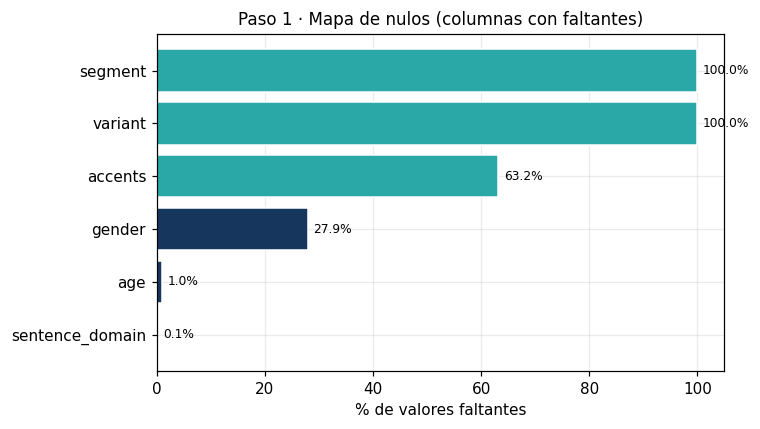

In [8]:
df = eda.paso1(df)        # ejecuta la limpieza y, de paso, guarda figuras/fig1_nulos.png
Image('figuras/fig1_nulos.png')

## Paso 2 — Anatomía Numérica (una variable)
> *Histograma y caja-y-bigotes leen los mismos datos de forma distinta: forma de la distribución vs. outliers.*


PASO 2 — ANATOMÍA NUMÉRICA (una variable a la vez)


Figuras 2-4 generadas (histogramas, box plots, barras categóricas).
  gender: {'female_feminine': np.int64(16079), 'unknown': np.int64(6340), 'male_masculine': np.int64(308)}
  concentración hablantes: 1 hablante aporta 2013 clips (8.9% del total).


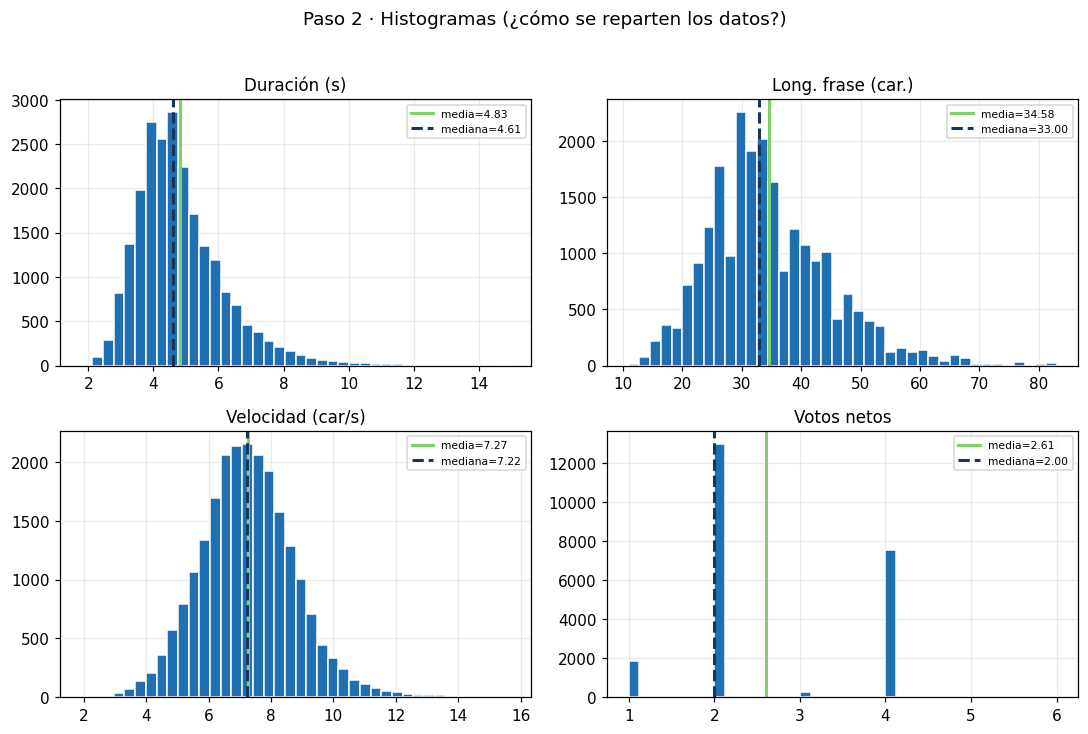

In [9]:
eda.paso2(df)
Image('figuras/fig2_histogramas.png')

**Histogramas.** `dur_s` y `n_chars` son unimodales y ligeramente asimétricas a la derecha (colas de clips
largos). `cps` (velocidad) se concentra ~7 car/s: coherente con habla natural. `net_votes` es casi constante
(validación con pocos votos).

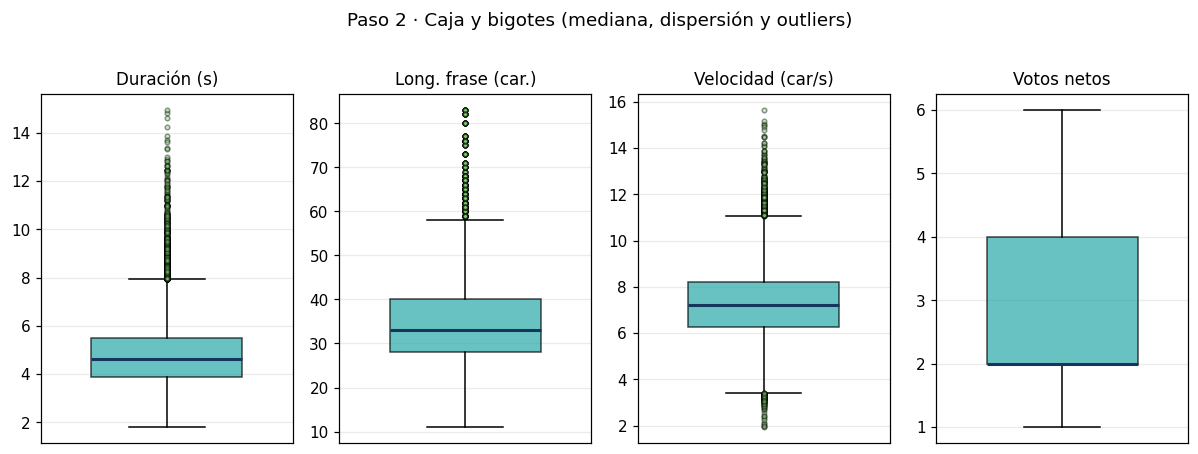

In [10]:
Image('figuras/fig3_boxplots.png')

**Caja y bigotes.** Exponen los *outliers* (puntos fuera de los bigotes IQR). En `dur_s` y `cps` aparecen
colas de valores extremos → clips muy largos/cortos o con **desajuste audio-texto** (velocidades imposibles),
candidatos a depurar antes de entrenar.

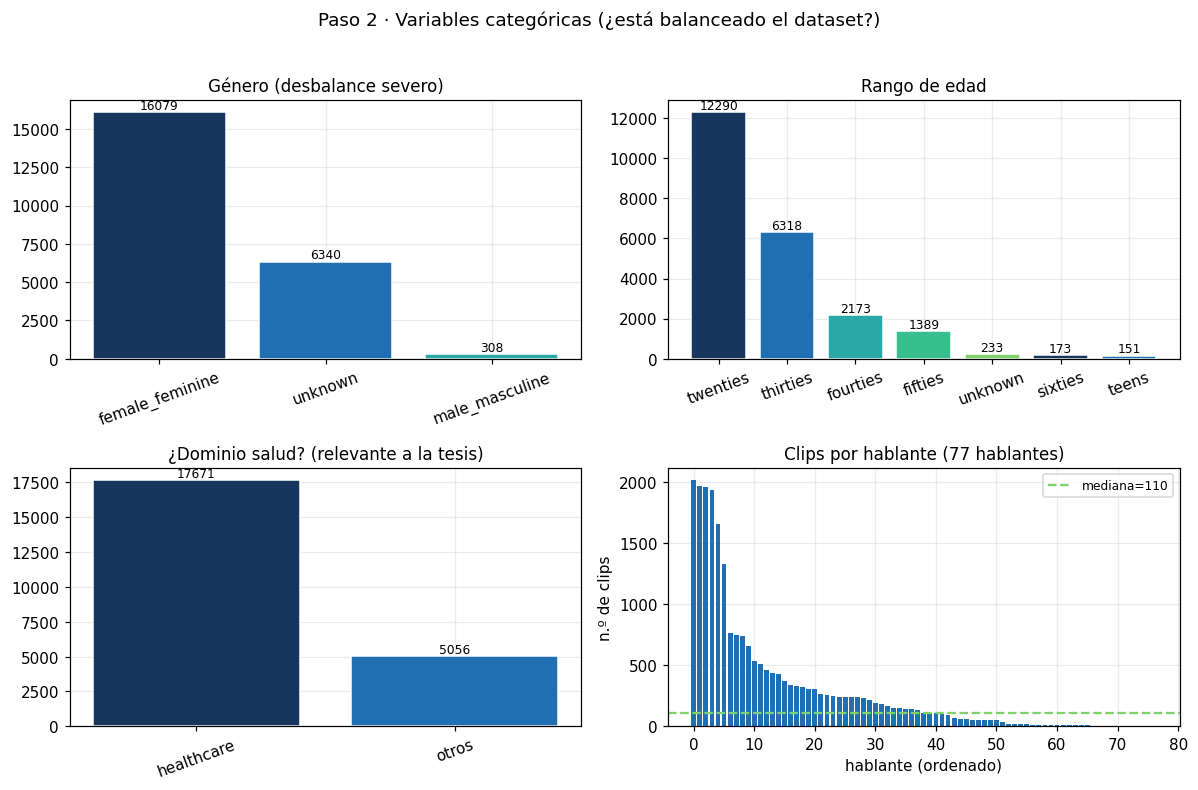

In [11]:
Image('figuras/fig4_barras_categoricas.png')

**Barras categóricas — el peligro del desbalance.** Hallazgos críticos:
- **Género fuertemente desbalanceado**: 16 079 `female` vs **308** `male` (y 6 340 `unknown`). El ASR
  aprenderá sobre todo voz femenina → sesgo a documentar.
- **Edad** concentrada en `twenties`/`thirties`.
- **Dominio salud**: ~**78 %** de los clips tocan `healthcare` → buena noticia para la tesis médica.
- **Hablantes**: un solo hablante aporta **~8,9 %** del corpus → concentración que refuerza la necesidad de
  partición por hablante.

## Paso 3 — Conexiones Ocultas (dos variables)
> *El número engaña; el gráfico no.* Por eso se usan **dispersión + Pearson + Spearman + mapa de calor**.


PASO 3 — CONEXIONES OCULTAS (dos variables: correlación)


n_chars~dur_s  Pearson=0.71  Spearman=0.71
dur_s~cps      Pearson=-0.25  Spearman=-0.20
Figura 6 (heatmaps Pearson/Spearman) generada.


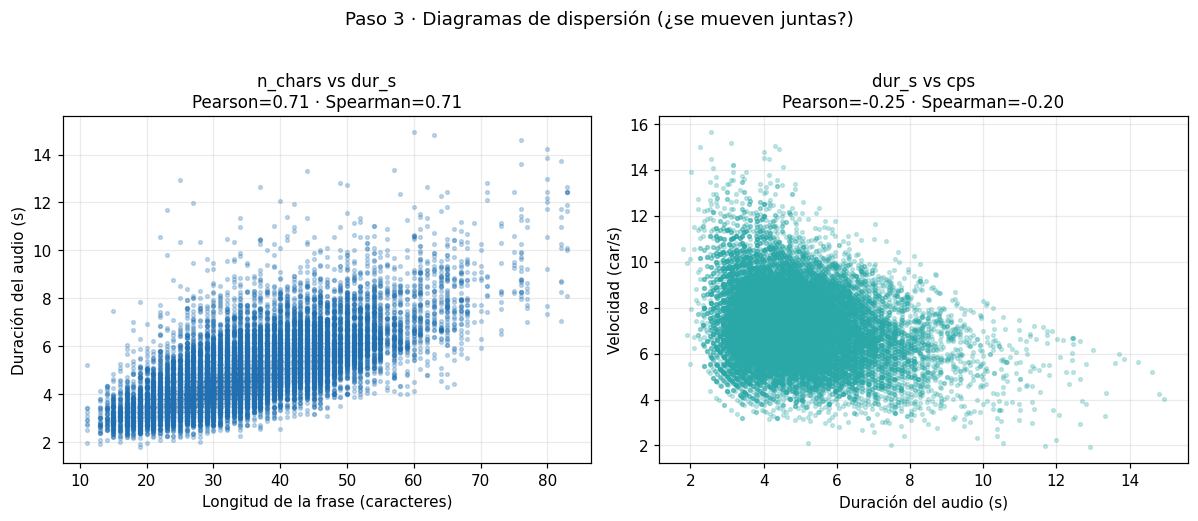

In [12]:
eda.paso3(df)
Image('figuras/fig5_dispersion.png')

**Dispersión.** `n_chars` vs `dur_s` sube en diagonal (relación **positiva**): frases más largas → audios
más largos (Pearson≈Spearman≈0,71, relación lineal y robusta). `dur_s` vs `cps` es débilmente **negativa**
(≈−0,25): en clips muy cortos la velocidad aparente se dispara (efecto de borde).

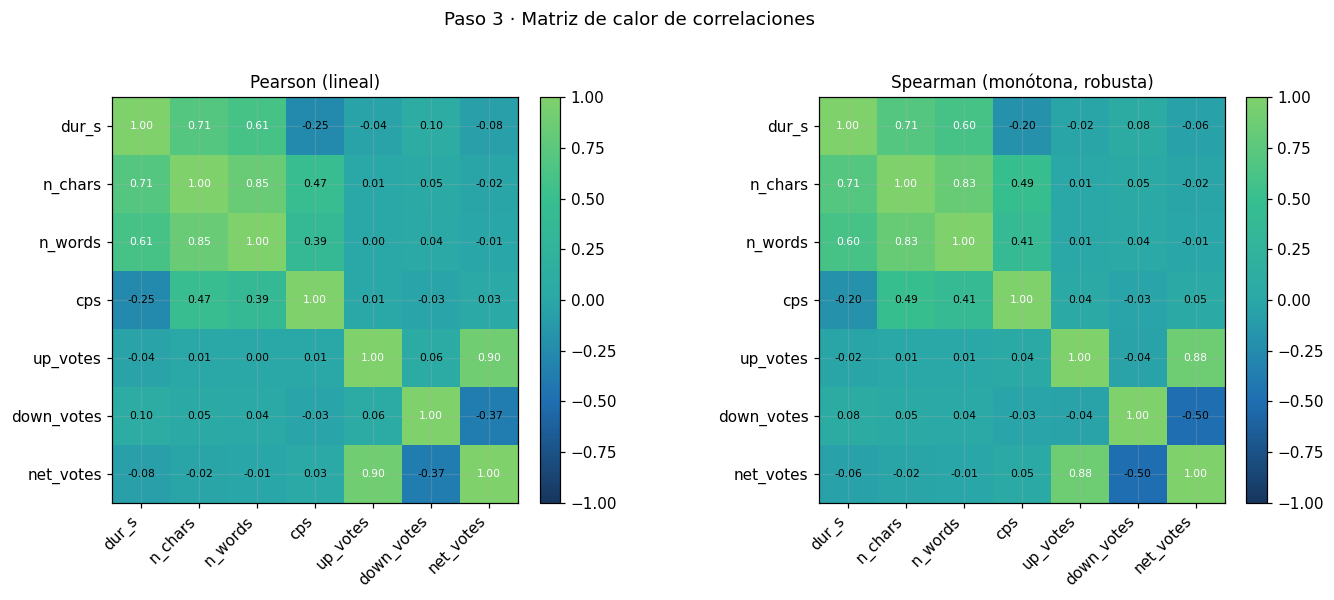

In [13]:
Image('figuras/fig6_heatmaps.png')

**Mapa de calor — por qué Pearson *y* Spearman.** Casi idénticos en relaciones lineales
(`dur_s~n_chars`), pero divergen donde importa: `down_votes~net_votes` da **−0,37 (Pearson)** frente a
**−0,50 (Spearman)**. Spearman, al basarse en rangos, es **robusta a outliers y a no-normalidad**: capta la
monotonía que Pearson diluye. `n_chars~n_words` ≈0,85 (redundancia esperable: miden lo mismo). La correlación
alta `up_votes~net_votes` es trivial (net = up−down con down≈0).

## Paso 4 — La Variable Objetivo
> *Separa todo por lo que quieres predecir.* Para la tesis médica, el eje de interés es **`is_healthcare`**.


PASO 4 — LA VARIABLE OBJETIVO (is_healthcare: foco de la tesis)


dur_s    salud(med=4.54) vs otros(med=4.79) Mann-Whitney p=1.09e-33
n_chars  salud(med=32.00) vs otros(med=36.00) Mann-Whitney p=1.85e-85
cps      salud(med=7.15) vs otros(med=7.44) Mann-Whitney p=2.55e-35
Clips de salud: 17671 (77.8% del corpus limpio).


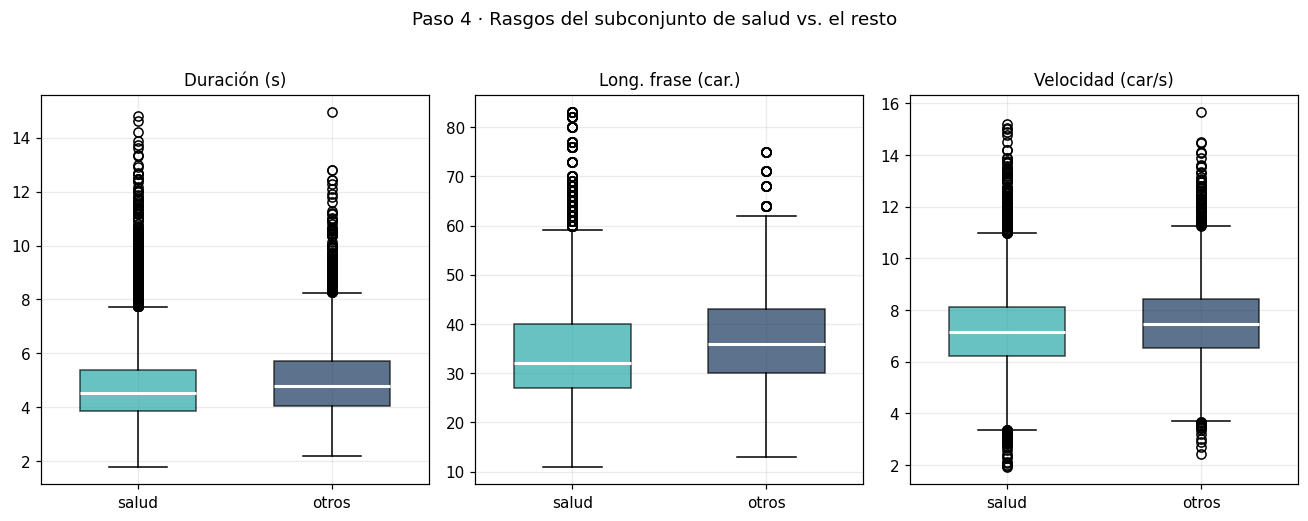

In [14]:
eda.paso4(df)
Image('figuras/fig7_objetivo.png')

**Cruces por objetivo.** El subconjunto de **salud** tiene frases ligeramente **más cortas** (mediana 32
vs 36 caracteres) y algo más lentas; las diferencias son pequeñas en magnitud pero **estadísticamente
significativas** (Mann-Whitney *p*≪0,001) por el gran *n*. Implicación: el dominio clínico está bien
representado y es homogéneo con el resto del corpus, sin sesgos de forma que compliquen el ajuste.

## Veredicto final — dataset limpio
Con las 8 herramientas en orden (**primero limpiar; luego una a una; luego de a dos; al final el objetivo**)
cubrimos la exploración. Escribimos el dataset depurado apto para entrenar:

In [15]:
eda.escribir_limpio(df)
limpio = pd.read_csv('dataset_limpio.csv')
print('dataset_limpio.csv:', limpio.shape)
limpio.head()


DATASET LIMPIO (apto para entrenar el ASR)


Criterio de inclusión: sin outlier IQR (dur_s, cps) y net_votes>0.
Filas: 22727 (crudo validado) -> 21653 (limpio) [-1074 filas, 4.7%].
Escrito: dataset_limpio.csv  (21653 filas x 16 col.)
dataset_limpio.csv: (21653, 16)


,client_id,path,sentence,domains,is_healthcare,n_domains,age,gender,accents,up_votes,down_votes,net_votes,dur_s,n_chars,n_words,cps
0,0af18d417177a707fb1bcb22e6b23aa10944f4e44ec80e...,common_voice_qxp_42192187.mp3,Irqikuna paykunapura qatipayanakunku.,agriculture_food;finance;healthcare;nature_env...,1,4,unknown,unknown,unknown,2,0,2,4.968,37,3,7.447665
1,76b24fbe885ee8fdad9aa7dd591b82c6fa01fdc5eeb366...,common_voice_qxp_48799942.mp3,Juan wayqichampaq waqayninta pichan.,agriculture_food;general;nature_environment,0,3,thirties,unknown,Puno,4,0,4,5.040,36,4,7.142857
2,87382b51a62cecd09092de5114d0bb779a4e61ce39e6e7...,common_voice_qxp_48816803.mp3,Hayk'aqmi runa Killaman chayarqan?,agriculture_food;general;healthcare,1,3,twenties,female_feminine,Puno|Macusani - Puno,6,0,6,4.860,34,4,6.995885
3,cbd0c73038ebd1636ed7d8211b650f8b4e47dedf03168b...,common_voice_qxp_48887267.mp3,Pipaqmi kay qillqasqa?,agriculture_food;general;healthcare,1,3,fifties,female_feminine,unknown,2,0,2,4.680,22,3,4.700855
4,e0c301044db611e861f7117cfcc2ee744f03bffd69122a...,common_voice_qxp_48781894.mp3,Iskay urququnaq chaupinpi payqa tiyan.,agriculture_food;general;history_law_government,0,3,thirties,female_feminine,unknown,2,0,2,4.896,38,5,7.761438


**Resumen de la limpieza (replicable con `python eda_limpieza.py`):**
1. Eliminadas columnas vacías/constantes/redundantes (`variant`, `segment`, `locale`, `sentence_id`).
2. `sentence_domain` normalizado → `domains`, `n_domains`, `is_healthcare` (76 filas malformadas corregidas).
3. Nulos demográficos (`age`, `gender`, `accents`) → `unknown` (sin perder clips).
4. Outliers IQR en `dur_s`/`cps` marcados y excluidos del set de entrenamiento (−4,7 %).
5. Resultado: **22 727 → 21 653 filas** limpias, con la partición por frase/hablante pendiente de aplicar en el *split* para evitar fuga.